# Programming Activity 3.1 | Polynomial Regression

Name: Abon, Benedict Aldous A.<br>
Course/Section: CPE 312 - CPE31S3<br>
Date Performed: 8/4/26<br>
Date Submitted: 8/4/26<br>
Instructor: Engr. Robin Valenzuela

#### Objective(s):

This activity aims to perform regression analysis using polynomial regression

#### Intended Learning Outcomes (ILOs):
* Demonstrate how to build a regression model to predict the outcome using polynomial regression.
* Evaluate the performance of the regression model using polynomial regression

#### Resources:
* Jupyter Notebook
* internet_traffic_hist.csv




#### Procedure:

#### Using numpy polyfit to perform polynomial regression
Import the libraries and the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from sklearn.metrics import r2_score
from scipy.optimize import curve_fit

Load the dataset

In [3]:
internet = 'internet_traffic_hist-2.csv'

df_hist = pd.read_csv(internet)
df_hist.head(11)

,traffic,year
0,100.000000,2005
1,126.933755,2006
2,160.303757,2007
3,203.390603,2008
4,241.292566,2009
5,308.791823,2010
6,379.980659,2011
7,495.840568,2012
8,616.207252,2013
9,752.103483,2014


Build the first order polynomial using numpy polyfit

The slope of line is 79.52710966244513.
The y intercept is -159457.12265833947.
The best fit simple linear regression line is 79.52710966244513x + -159457.12265833947.


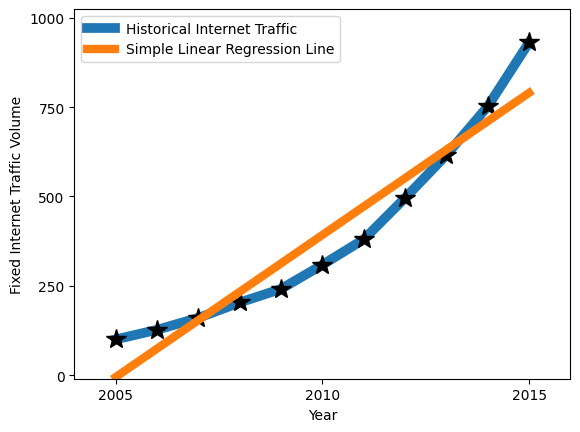

In [4]:
order = 1

# XY Plot of year and traffic
x = df_hist.year
y = df_hist.traffic

m, b = np.polyfit(x,y,order)

plt.plot(x, y, label = 'Historical Internet Traffic', linewidth = 7)
plt.plot(x, y,'*k', markersize = 15, label ='')
plt.plot(x, m*x + b, '-', label = 'Simple Linear Regression Line', linewidth = 6)

print ('The slope of line is {}.'.format(m))
print ('The y intercept is {}.'.format(b))
print ('The best fit simple linear regression line is {}x + {}.'.format(m,b))


#Increase sligthly the axis sizes to make the plot more clear
plt.axis([x.iloc[0]-1, x.iloc[-1]+1, y.iloc[0]*-0.1, y.iloc[-1]*1.1])

# Add axis labels
plt.xlabel('Year')
plt.ylabel('Fixed Internet Traffic Volume')
plt.legend(loc = 'upper left')

# Increase default font size
plt.rcParams.update({'font.size': 26})
plt.show()

### Observation
The code above shows how to create a first order polynomial regression. Its highlight is the use of numpy polyfit method, which models the x and y variables into a n-degree powered polynomial. In this case, a first order is made, making the order equal to one. We also take the recorded year as independent variable x and internet traffic data as dependent variable y. We then plotted the internet traffic data and its linear regression. For the linear regression line, we used the formual m*x + b as y. The code then returns the slope of the regression line, its y-intercept, and best fit simple linear regression line.

Build the model using Higher Order Polynomial (1 to 4)

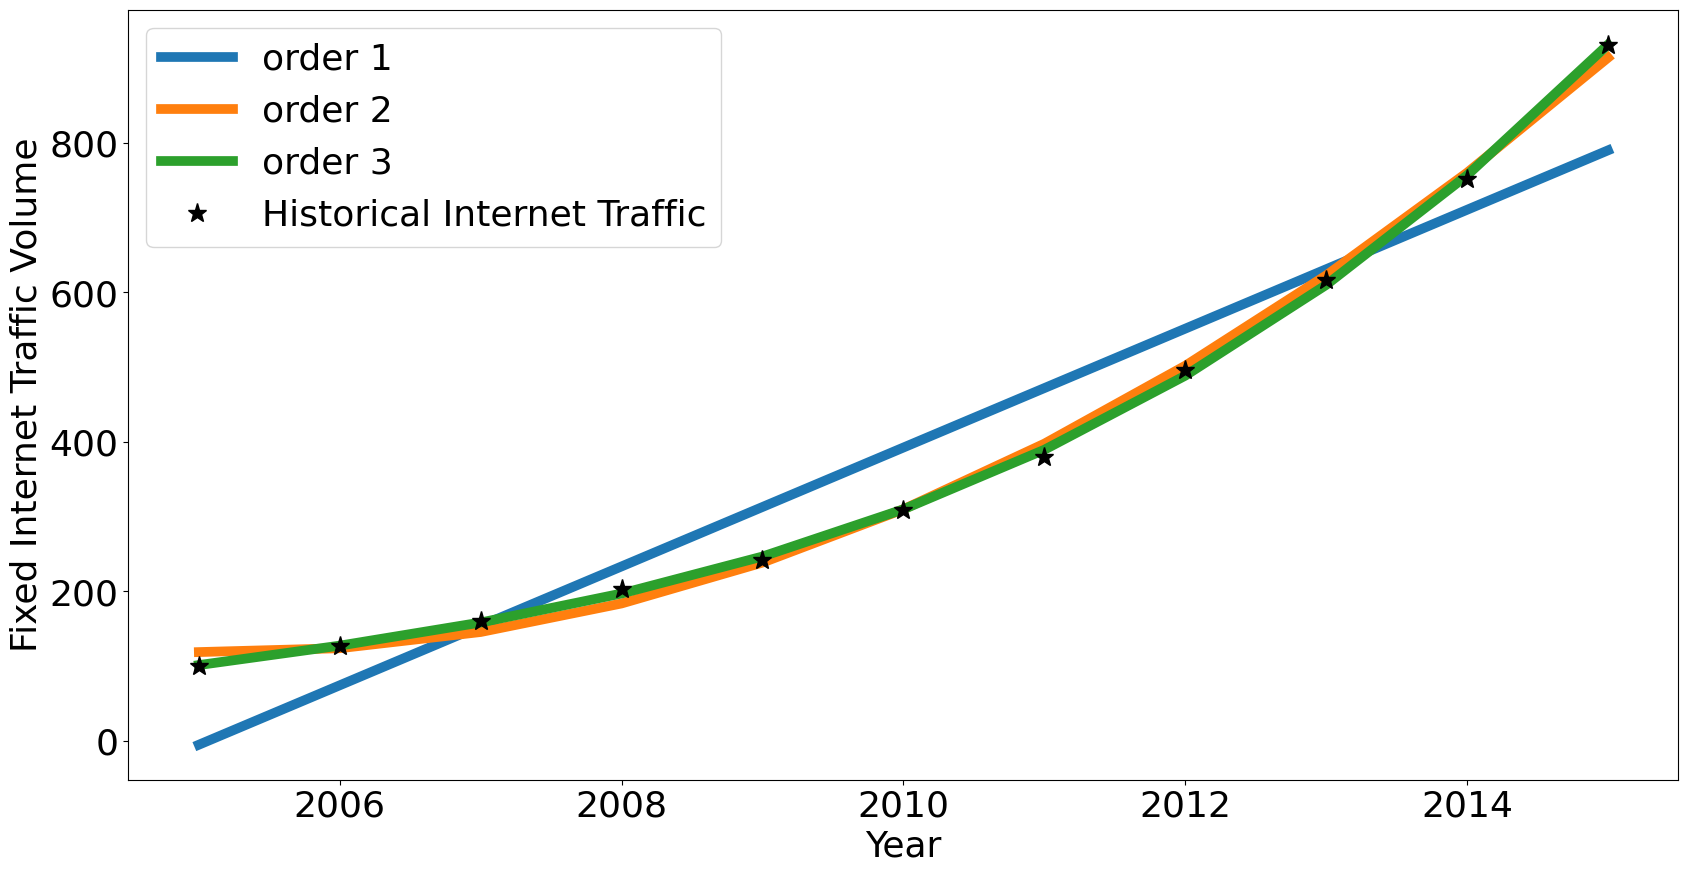

In [5]:
models = []       # to store polynomial model parameters (list of poly1d objects)
errors_hist = []  # to store the absolute errors for each point (2005-2015) and for each model (list of numpy arrays )
mse_hist = []     # to store the MSE for each model (list of numpy floats)

#Try polynomial models with increasing order
for order in range(1,4):
    # Fit polynomial model
    p = (np.poly1d(np.polyfit(x, y, order)))
    models.append(p)

plt.figure(figsize = (20,10))

# Visualize polynomial models fit
for model in models[0:3]:
    plt.plot(x, model(x), label = 'order ' + str(len(model)), linewidth = 7)

plt.plot(x, y, '*k', markersize = 14, label = 'Historical Internet Traffic', linewidth = 7)
plt.legend(loc = 'upper left')

# Add axis labels
plt.xlabel('Year')
plt.ylabel('Fixed Internet Traffic Volume')

plt.show()

### Observation
Introducing higher order polynomial models made the regression line more curved, specifically increasing the order to 2 or 3. This made the regression line fit the internet traffic data fit with each other more, rather than using 1 as the polynomial order.

Calculate the error for each order

In [6]:
# Calculate and store the erros
models = []       # to store polynomial model parameters (list of poly1d objects)
errors_hist = []  # to store the absolute errors for each point (2005-2015) and for each model (list of numpy arrays )
mse_hist = []     # to store the MSE for each model (list of numpy floats)

#Try polynomial models with increasing order
for order in range(1,4):
    # Fit polynomial model
    p = (np.poly1d(np.polyfit(x, y, order)))
    models.append(p)

    e = np.abs(y-p(x))        # absolute error
    mse = np.sum(e**2)/len(df_hist) # mse

    errors_hist.append(e)   #Store the absolute errors
    mse_hist.append(mse) # Store the mse

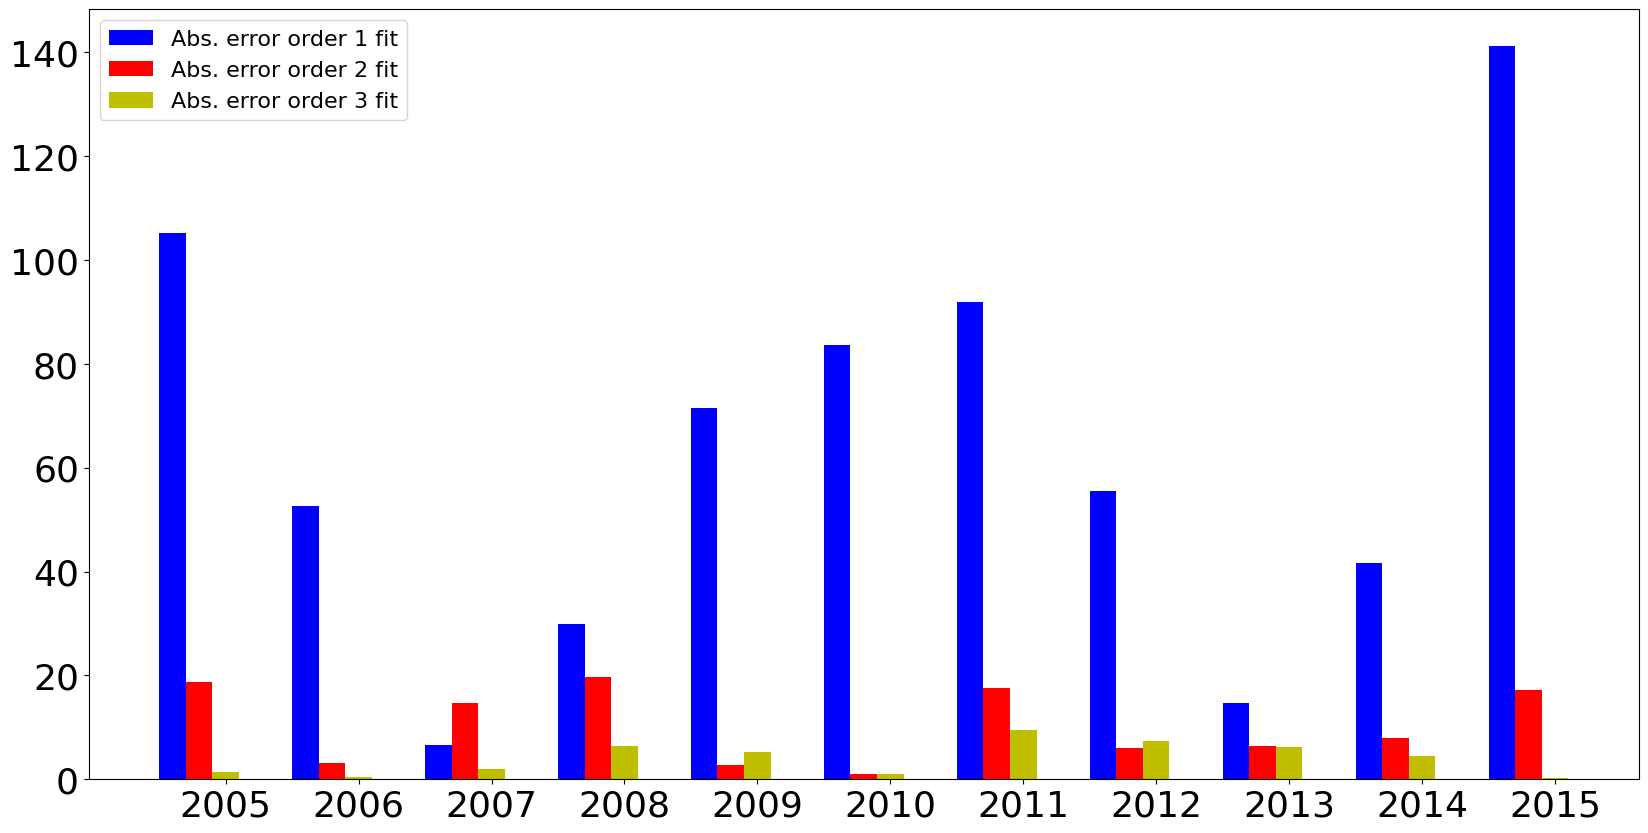

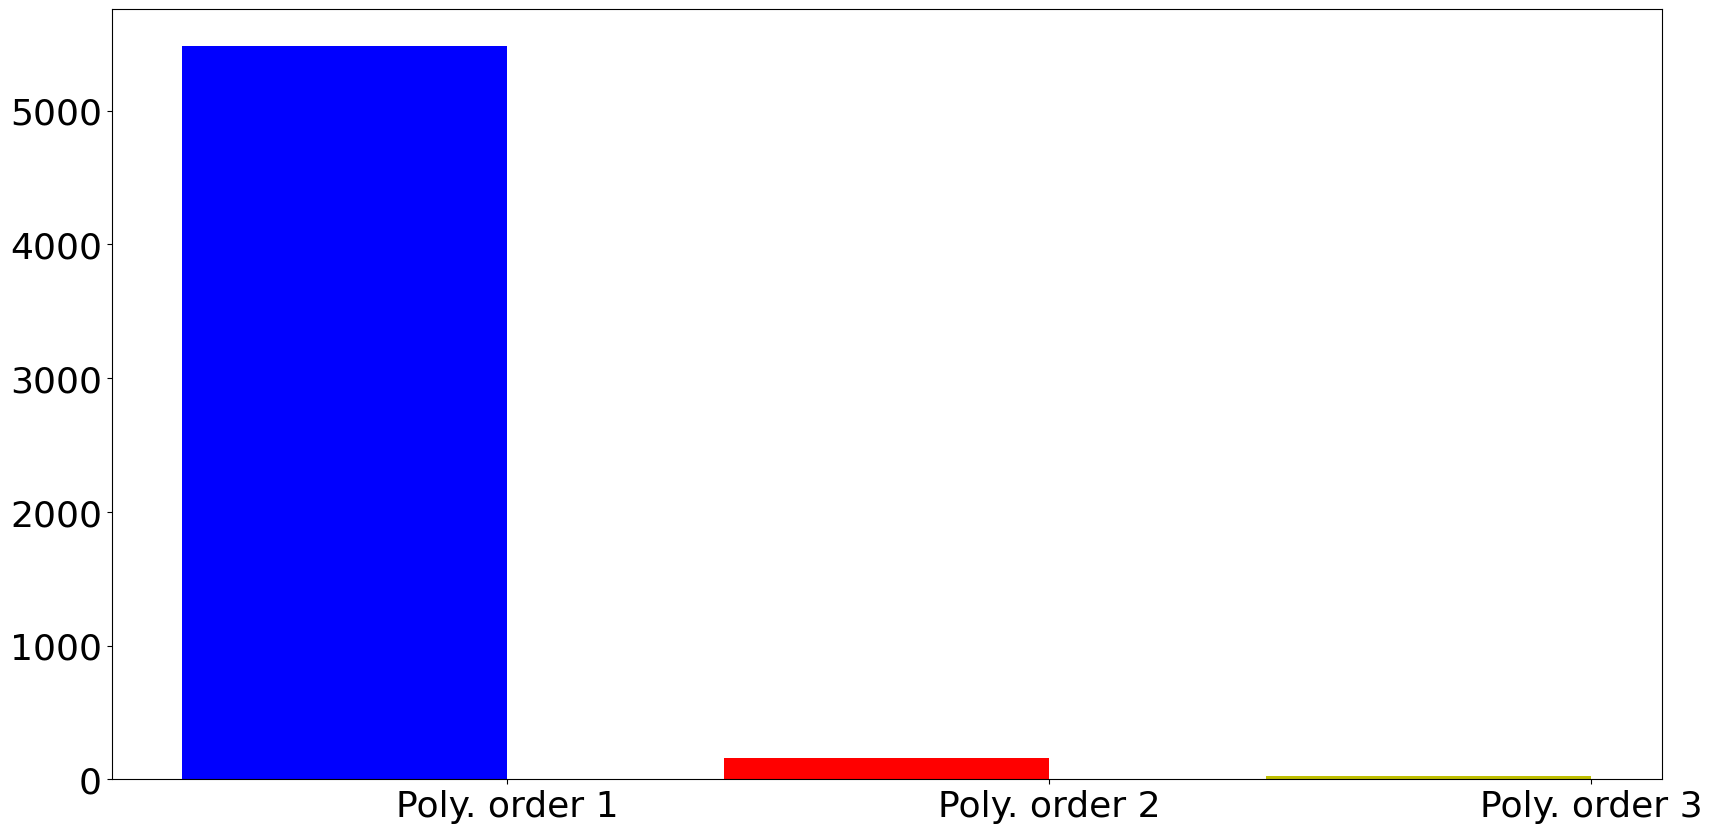

In [7]:
# Visualize fit error for each year

x = df_hist.year
width = 0.2   #size of the bar

fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111)

p1 = ax.bar( x, errors_hist[0], width, color = 'b', label = 'Abs. error order 1 fit')
p2 = ax.bar( x + width, errors_hist[1], width, color = 'r', label = 'Abs. error order 2 fit')
p3 = ax.bar( x + 2*width, errors_hist[2], width, color = 'y', label = 'Abs. error order 3 fit')

# "Prettyfy" the bar graph
ax.set_xticks(x+2*width)
ax.set_xticklabels(x)
plt.legend(loc = 'upper left', fontsize =16)
plt.show()

#Visualise MSE for each model
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111)

x = np.array([0,1,2])
width = .6   #size of the bar

p1 = ax.bar( x[0], mse_hist[0], width, color = 'b', label = 'pred. error order 1 fit')
p2 = ax.bar( x[1], mse_hist[1], width, color = 'r', label = 'pred. error order 2 fit')
p3 = ax.bar( x[2], mse_hist[2], width, color = 'y', label = 'pred. error order 3 fit')

ax.set_xticks(x+width/2)
ax.set_xticklabels(['Poly. order 1', 'Poly. order 2', 'Poly. order 3'])
plt.show()

### Interpret the result of the fit error for each year
Based on the fit error visualizations above, we can see a significant mean squared error in using polynomial order 1, while lesser errors in using orders 2 and 3. Between polynomial orders 2 and 3, the polynomial order 3 showed less errors than the other, making it the best fit regression line for the given data. We can also see varying errors recorded in the internet traffic data per year. The visualizations let us understand which model best fits the data.

In [8]:
# Polynomial function order
order = 3

x = df_hist.year.values      # regressor
y = df_hist.traffic.values   # regressand

# Fit the model, return the polynomial parameter values in a numpy array such that
# y = p[0]*x**order + p[1]*x*(order-1) ...

p_array = np.polyfit(x,y,order)

print(type(p_array), p_array)

# poly1d is a convenience class, used to encapsulate “natural” operations on polynomials
# so that said operations may take on their customary form in code

# wrap the p_array in a poly1 object
p = np.poly1d(p_array)

print(type(p), p)

# use the poly1d object to evaluate the value of the polynomial in a specific point
print('The value of the polynomial for x = 2020 is : {} '.format(p(2020)))

# compute the absolute error for each value of x and the MSE error for the estimated polynomial model
e = np.abs(y-p(x))
mse = np.sum(e**2)/len(x)

print('The estimated polynomial parameters are: {}'.format(p))
print('The errors for each value of x, given the estimated polynomial parameters are: \n {}'.format(e))
print('The MSE is :{}'.format(mse))

<class 'numpy.ndarray'> [ 4.83129404e-01 -2.90500578e+03  5.82252085e+06 -3.89005387e+09]
<class 'numpy.poly1d'>         3        2
0.4831 x - 2905 x + 5.823e+06 x - 3.89e+09
The value of the polynomial for x = 2020 is : 2328.5784521102905 
The estimated polynomial parameters are:         3        2
0.4831 x - 2905 x + 5.823e+06 x - 3.89e+09
The errors for each value of x, given the estimated polynomial parameters are: 
 [1.30743027 0.39125264 2.02722693 6.32983208 5.28394403 0.93069802
 9.41692212 7.34010081 6.27729748 4.48133933 0.16291521]
The MSE is :25.17218620372407


### Observation
The results of the code above lets us understand the polynomial regression model that uses order 3. It further verifies its fit by returning the values associated with the model.

#### Using sklearn to perform polynomial regression

Import the necessary libraries

In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

Training the Polynomial Regression model  using degree 3

In [10]:
poly_reg = PolynomialFeatures(degree=3)
X_poly = poly_reg.fit_transform(x.reshape(-1, 1))

In [11]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,y)


LinearRegression()

Predict the result using polynomial regression model

In [12]:
y_pred = lin_reg.predict(X_poly)


In [13]:
df = pd.DataFrame({'Real Values': y, 'Predicted Values':y_pred})

In [14]:
df

,Real Values,Predicted Values
0,100.000000,101.241620
1,126.933755,127.295559
2,160.303757,158.270686
3,203.390603,197.068289
4,241.292566,246.589652
5,308.791823,309.736069
6,379.980659,389.408823
7,495.840568,488.509205
8,616.207252,609.938500
9,752.103483,756.598000


Visualize the Polynomial Regression results

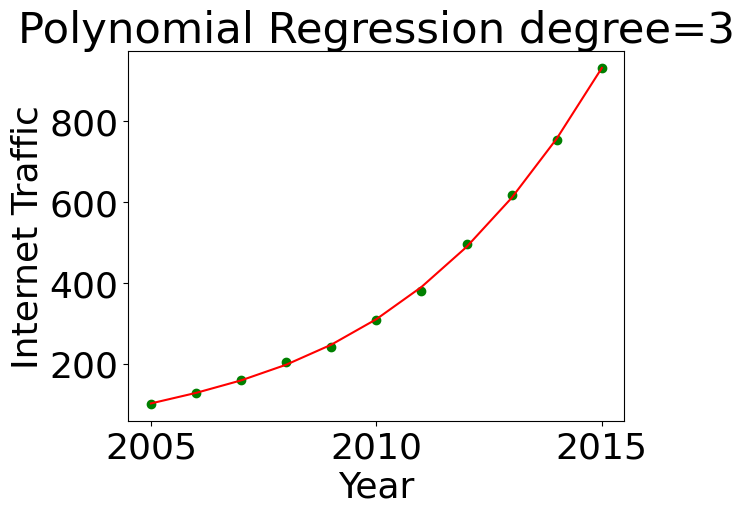

In [15]:
plt.scatter(x, y, color='green')
plt.plot(x, y_pred, color = 'red')

plt.title("Polynomial Regression degree=3")
plt.xlabel('Year')
plt.ylabel('Internet Traffic')


plt.show();

### Observation
The figure above shows the implementation of the polynomial regression on internet traffic data. The green dots represent the real values, while the red line represents the predicted values. The predicted values were created using the predict method, where we used the x values as reference. In return, we get an accurate model that best fits the real values.

Supplementary Activity:
* Choose your own dataset
* Import the dataset
* Perform polynomial regression using sklearn and polyfit
* Measure the performance for each polynomial degree.
* Plot the performance of the model for each polynomial degree.


### Brent Oil Prices Dataset
https://www.kaggle.com/datasets/mabusalah/brent-oil-prices

In [16]:
# Import dataset (manual)
df = pd.read_csv('BrentOilPrices.csv')
df


,Date,Price
0,20-May-87,18.63
1,21-May-87,18.45
2,22-May-87,18.55
3,25-May-87,18.60
4,26-May-87,18.63
...,...,...
9006,"Nov 08, 2022",96.85
9007,"Nov 09, 2022",93.05
9008,"Nov 10, 2022",94.25
9009,"Nov 11, 2022",96.37


In [17]:
df.shape


(9011, 2)

In [18]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9011 entries, 0 to 9010
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    9011 non-null   object 
 1   Price   9011 non-null   float64
dtypes: float64(1), object(1)
memory usage: 140.9+ KB


In [19]:
df.dtypes


,0
Date,object
Price,float64


In [20]:
df.describe()


,Price
count,9011.000000
mean,48.420782
std,32.860110
min,9.100000
25%,19.050000
50%,38.570000
75%,70.090000
max,143.950000


### Data cleaning

In [21]:
# Create copy
df_clean = df.copy()
df_clean


,Date,Price
0,20-May-87,18.63
1,21-May-87,18.45
2,22-May-87,18.55
3,25-May-87,18.60
4,26-May-87,18.63
...,...,...
9006,"Nov 08, 2022",96.85
9007,"Nov 09, 2022",93.05
9008,"Nov 10, 2022",94.25
9009,"Nov 11, 2022",96.37


In [22]:
# Check and remove missing values
df_clean.duplicated().sum()

np.int64(0)

In [23]:
# Date format
df_clean["Date"] = pd.to_datetime(df["Date"], errors="coerce")
# Extract year from date
df_clean["Date"] = df_clean["Date"].dt.year

# Price format
df_clean["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df_clean


/tmp/ipykernel_1197/1906808942.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean["Date"] = pd.to_datetime(df["Date"], errors="coerce")


,Date,Price
0,1987,18.63
1,1987,18.45
2,1987,18.55
3,1987,18.60
4,1987,18.63
...,...,...
9006,2022,96.85
9007,2022,93.05
9008,2022,94.25
9009,2022,96.37


In [24]:
# Group by year
df_clean = df_clean.groupby("Date")["Price"].mean()

# Limit to 2000-2022
df_clean = df_clean[df_clean.index >= 2000]
df_clean = df_clean[df_clean.index <= 2022]

# Remain index
df_clean = df_clean.reset_index()
df_clean

,Date,Price
0,2000,28.660672
1,2001,24.455720
2,2002,24.993255
3,2003,28.850814
4,2004,38.259693
5,2005,54.574553
6,2006,65.161765
7,2007,72.441160
8,2008,96.944348
9,2009,61.738770


In [25]:
# df after data cleaning
df_clean

,Date,Price
0,2000,28.660672
1,2001,24.455720
2,2002,24.993255
3,2003,28.850814
4,2004,38.259693
5,2005,54.574553
6,2006,65.161765
7,2007,72.441160
8,2008,96.944348
9,2009,61.738770


###Perform polynomial regression using sklearn and polyfit

The slope of line is 1.8745896537760502.
The y intercept is -3704.22510450842.
The simple linear regression line is 1.8745896537760502x + -3704.22510450842.


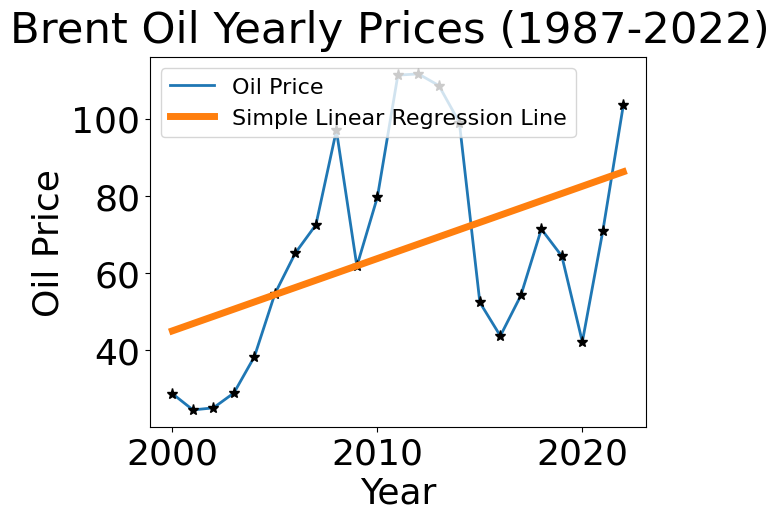

In [26]:
# Polynomial Regression (order 1)
order = 1

# x = Date
# y = Price
x = df_clean.Date
y = df_clean.Price

# Polyfit
m, b = np.polyfit(x, y, order)

# Plot
plt.plot(x, y, label='Oil Price', linewidth=2)
plt.plot(x, y,'*k', markersize=8, label ='')
plt.plot(x, m*x + b, '-', label='Simple Linear Regression Line', linewidth=5)

# Print slope, y-intercept, and simple linear regression line
print('The slope of line is {}.'.format(m))
print('The y intercept is {}.'.format(b))
print('The simple linear regression line is {}x + {}.'.format(m,b))

# Add axis labels
plt.xlabel('Year')
plt.ylabel('Oil Price')
plt.legend(loc='upper left', fontsize=16)
plt.suptitle('Brent Oil Yearly Prices (1987-2022)')

plt.show()

###Plot the performance of the model for each polynomial degree

In [27]:
# Multi-order Polynomial Models
models = []
errors_hist = []
mse_hist = []

# Orders 1-5
for order in range(1,6):
    p = (np.poly1d(np.polyfit(x, y, order)))
    models.append(p)

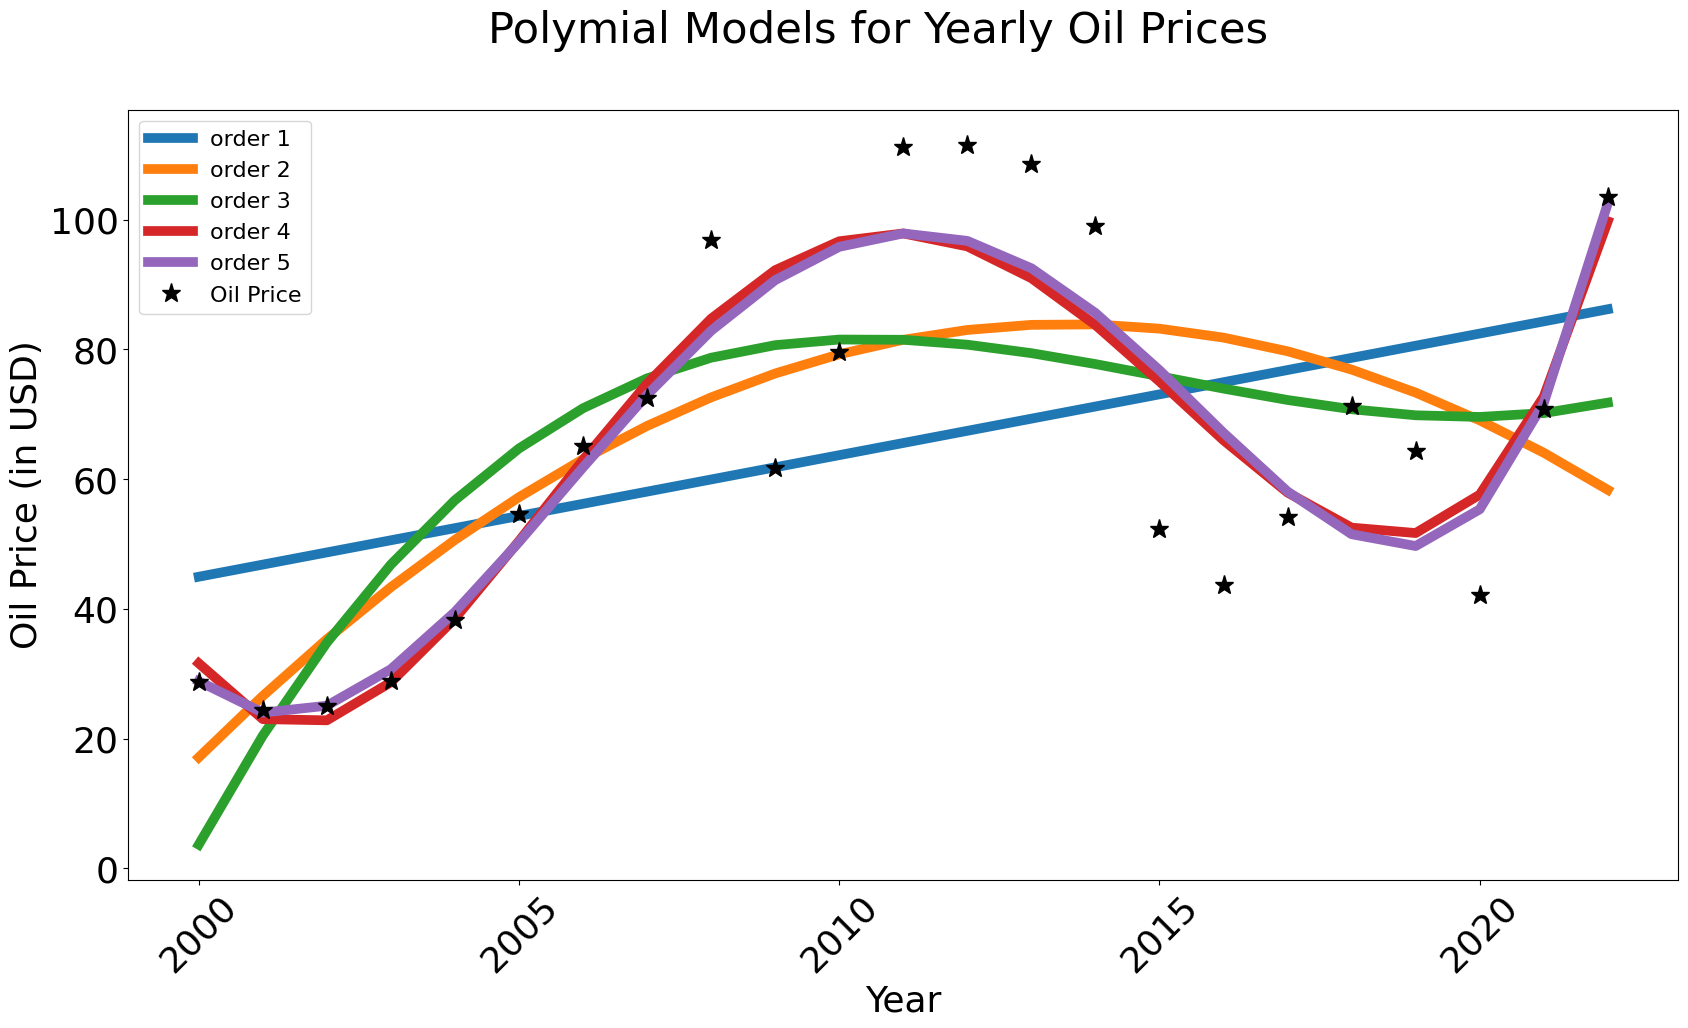

In [28]:
# Create plot
plt.figure(figsize=(20,10))

# Plot each regression line
for model in models[0:6]:
    plt.plot(x, model(x), label='order ' + str(len(model)), linewidth=7)

# Plot real value markers
plt.plot(x, y, '*k', markersize=14, label = 'Oil Price', linewidth=5)

# Labels
plt.suptitle("Polymial Models for Yearly Oil Prices")
plt.xlabel('Year')
plt.ylabel('Oil Price (in USD)')
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=16)

plt.show()

###Measure the performance for each polynomial degree


In [29]:
# Calculate errors

models = []
errors_hist = []
mse_hist = []

for order in range(1,6):
    p = (np.poly1d(np.polyfit(x, y, order)))
    models.append(p)

    e = np.abs(y-p(x)) # absolute error
    mse = np.sum(e**2)/len(df_hist) # mse

    errors_hist.append(e) #Store the absolute errors
    mse_hist.append(mse) # Store the mse

### Fit Error

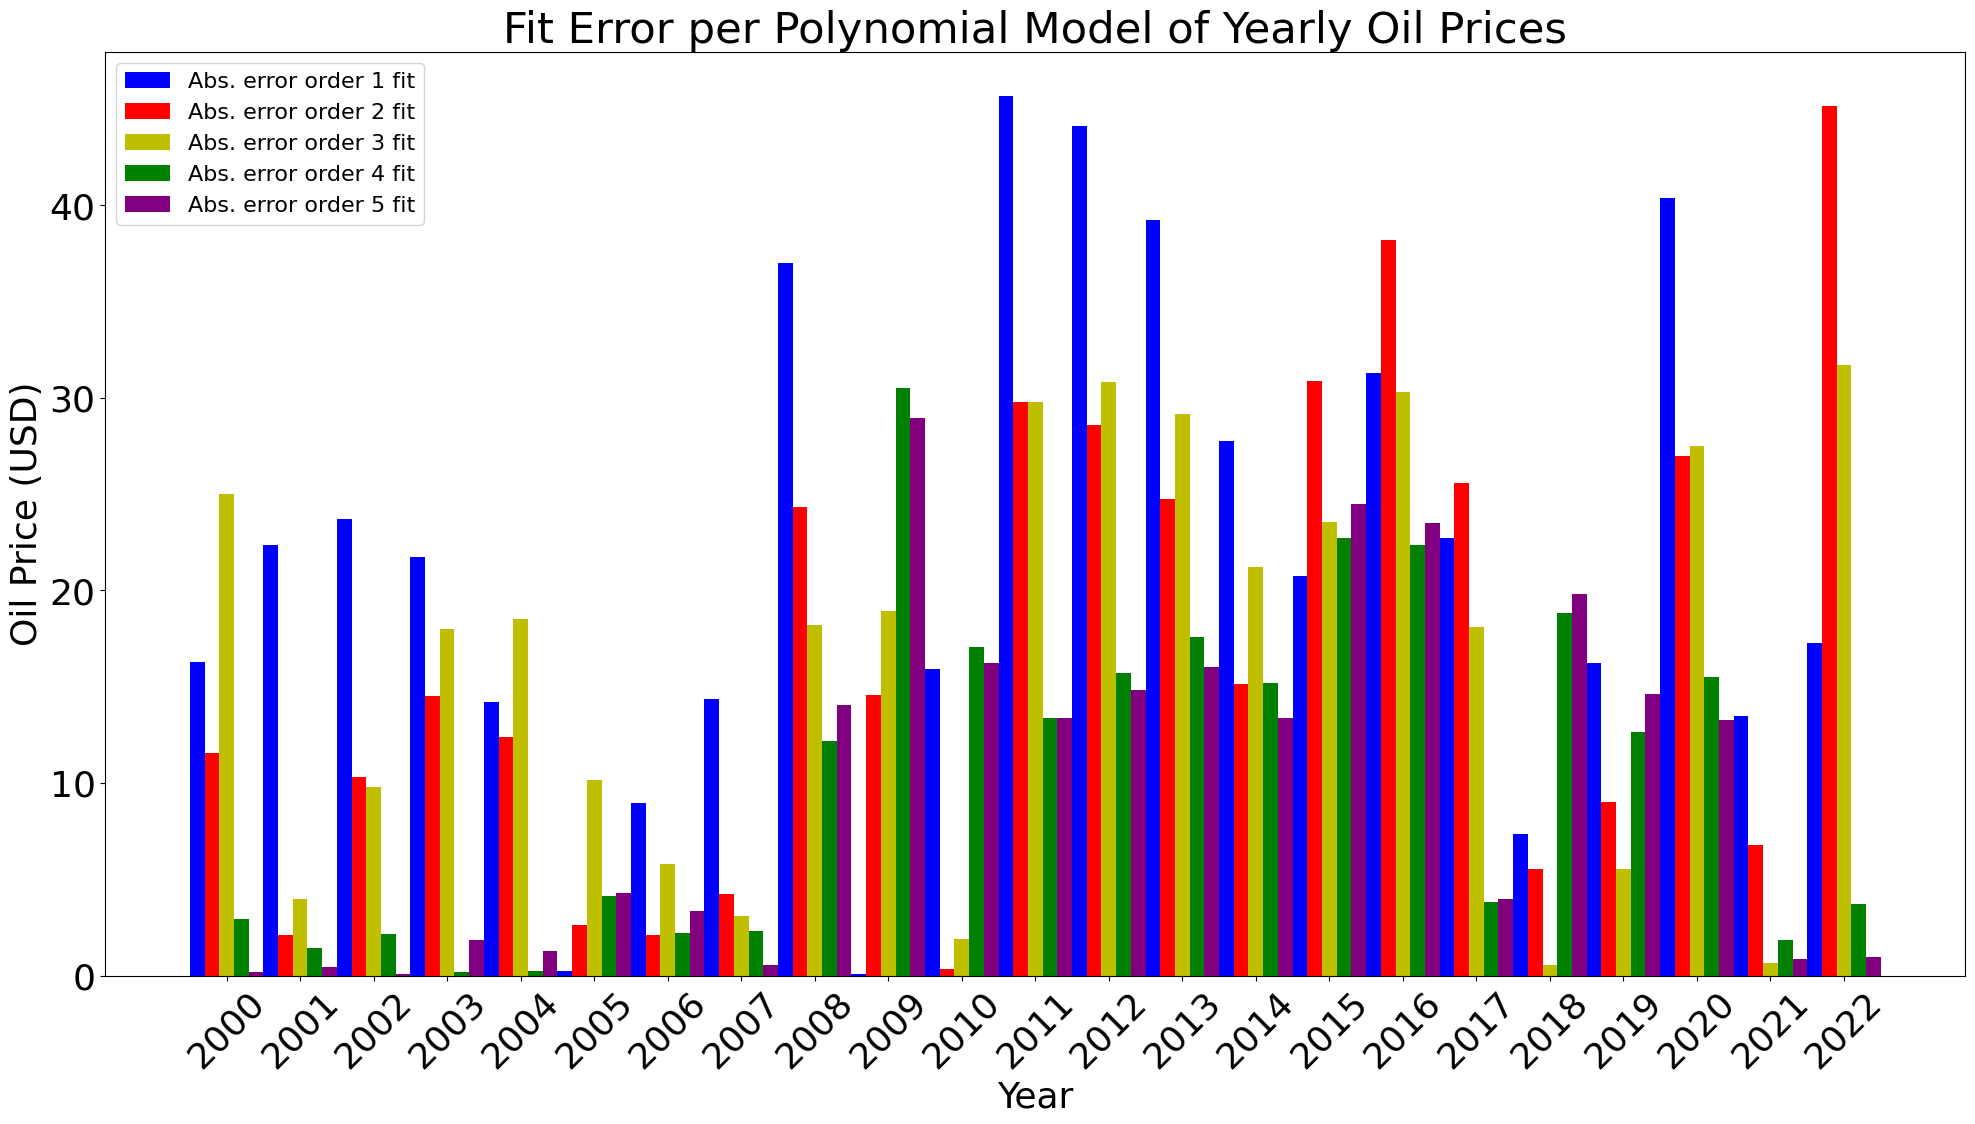

In [30]:
# Fit error per model

x = df_clean.Date
width = 0.2 # bar size

# Create absolute error per model bar graph
fig = plt.figure(figsize=(24,12))
ax = fig.add_subplot(111)

# Plot
p1 = ax.bar( x, errors_hist[0], width, color = 'b', label = 'Abs. error order 1 fit')
p2 = ax.bar( x + width, errors_hist[1], width, color = 'r', label = 'Abs. error order 2 fit')
p3 = ax.bar( x + 2*width, errors_hist[2], width, color = 'y', label = 'Abs. error order 3 fit')
p4 = ax.bar( x + 3*width, errors_hist[3], width, color = 'g', label = 'Abs. error order 4 fit')
p5 = ax.bar( x + 4*width, errors_hist[4], width, color = 'purple', label = 'Abs. error order 5 fit')

# 1st bar graph properties
ax.set_title("Fit Error per Polynomial Model of Yearly Oil Prices")
ax.set_xlabel("Year")
ax.set_ylabel("Oil Price (USD)")
ax.set_xticks(x+2*width)
ax.set_xticklabels(x, rotation=45)
plt.legend(loc = 'upper left', fontsize=16)

plt.show()

###MSE

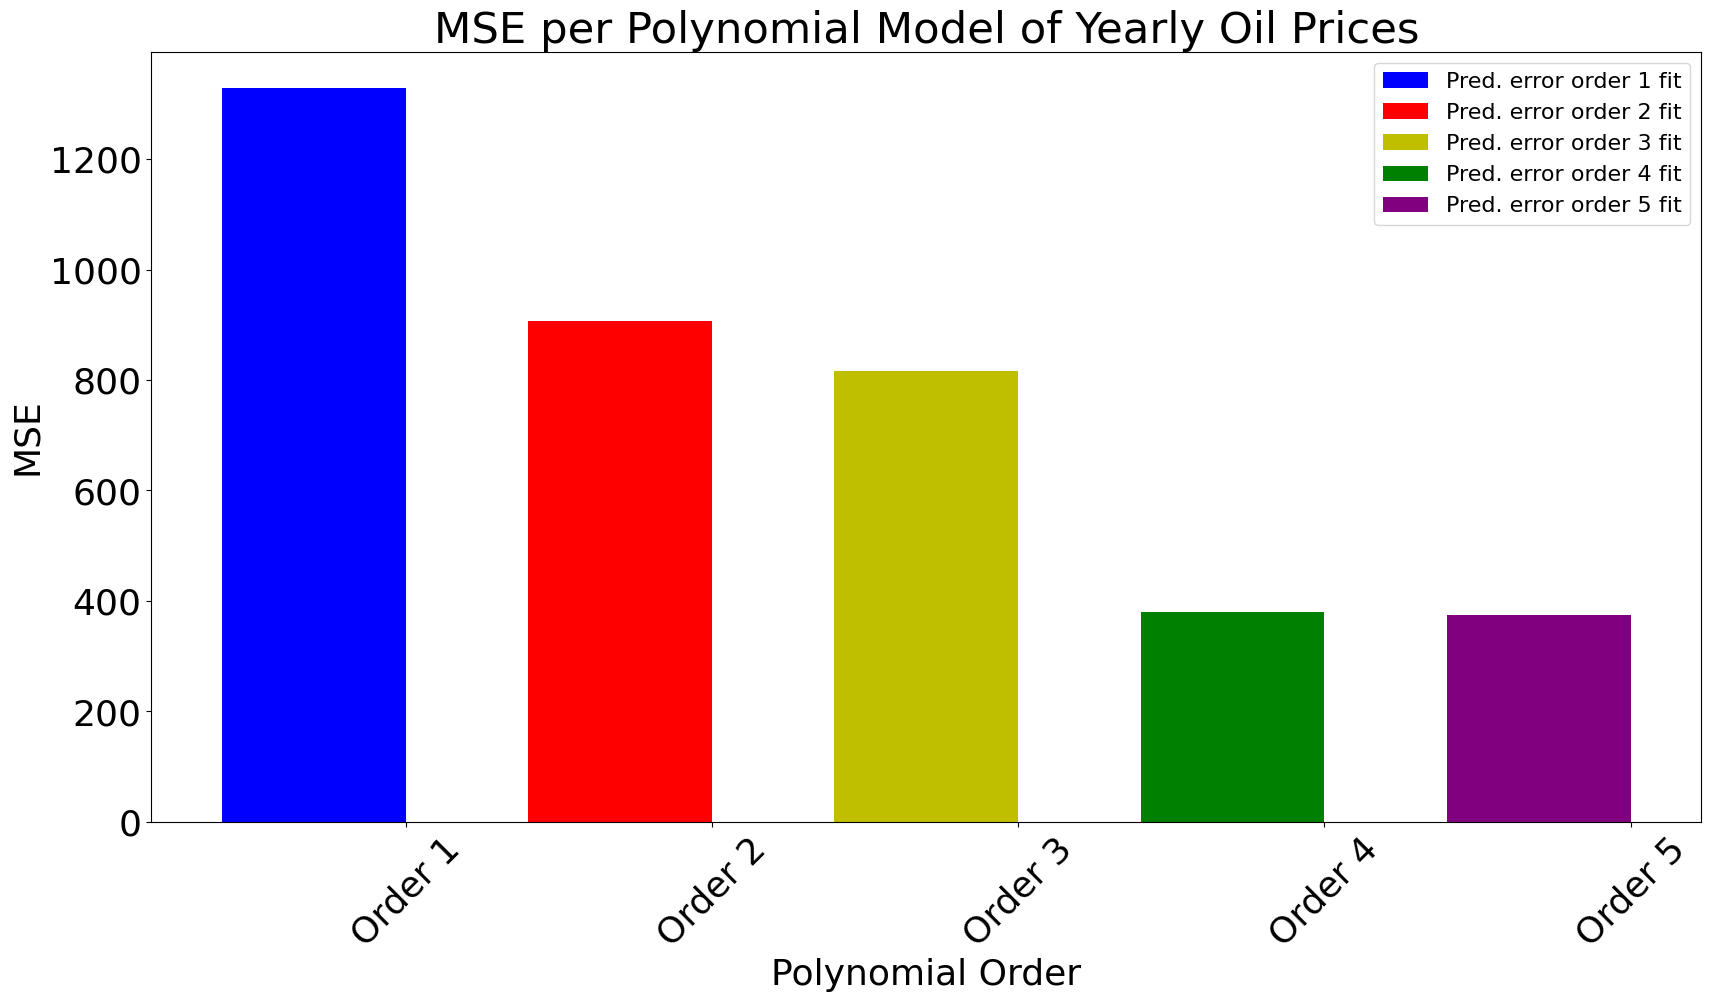

In [31]:
# MSE each model bar graph
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111)

x = np.array([0,1,2,3,4])
width = 0.6

# Plot
p1 = ax.bar(x[0], mse_hist[0], width, color='b', label='Pred. error order 1 fit')
p2 = ax.bar(x[1], mse_hist[1], width, color='r', label='Pred. error order 2 fit')
p3 = ax.bar(x[2], mse_hist[2], width, color='y', label='Pred. error order 3 fit')
p4 = ax.bar(x[3], mse_hist[3], width, color='g', label='Pred. error order 4 fit')
p5 = ax.bar(x[4], mse_hist[4], width, color='purple', label='Pred. error order 5 fit')

# 2nd bar graph properties
ax.set_title("MSE per Polynomial Model of Yearly Oil Prices")
ax.set_xlabel("Polynomial Order")
ax.set_ylabel("MSE")
ax.set_xticks(x+width/2)
ax.set_xticklabels(['Order 1', 'Order 2', 'Order 3', 'Order 4', 'Order 5'], rotation=45)
plt.legend(loc='upper right', fontsize=16)

plt.show()

### Training the Polynomial Regression Model using Degree 1

In [32]:
# Polynomial function order
order = 1

x = df_clean.Date.values # regressor
y = df_clean.Price # regressand
p_array = np.polyfit(x,y,order)

print(type(p_array), p_array)
p = np.poly1d(p_array)
print(type(p), p)
print('The value of the polynomial for x = 2020 is : {} '.format(p(2020)))

e = np.abs(y-p(x))
mse = np.sum(e**2)/len(x)

print('The estimated polynomial parameters are: {}'.format(p))
print('The errors for each value of x, given the estimated polynomial parameters are: \n {}'.format(e))
print('The MSE is :{}'.format(mse))

<class 'numpy.ndarray'> [ 1.87458965e+00 -3.70422510e+03]
<class 'numpy.poly1d'>  
1.875 x - 3704
The value of the polynomial for x = 2020 is : 82.44599611920148 
The estimated polynomial parameters are:  
1.875 x - 3704
The errors for each value of x, given the estimated polynomial parameters are: 
 0     16.293531
1     22.373073
2     23.710127
3     21.727158
4     14.192868
5      0.247401
6      8.960024
7     14.364829
8     36.993428
9      0.086740
10    15.909345
11    45.689585
12    44.121404
13    39.231131
14    27.771148
15    20.756499
16    31.309638
17    22.697422
18     7.361817
19    16.251562
20    40.344980
21    13.465250
22    17.282370
Name: Price, dtype: float64
The MSE is :635.0827977212482


In [33]:
poly_reg = PolynomialFeatures(degree=1)
X_poly = poly_reg.fit_transform(x.reshape(-1, 1))

In [34]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,y)


LinearRegression()

In [35]:
y_pred = lin_reg.predict(X_poly)


In [36]:
df = pd.DataFrame({'Real Values': y, 'Predicted Values':y_pred})

In [37]:
df

,Real Values,Predicted Values
0,28.660672,44.954203
1,24.455720,46.828793
2,24.993255,48.703382
3,28.850814,50.577972
4,38.259693,52.452562
5,54.574553,54.327151
6,65.161765,56.201741
7,72.441160,58.076331
8,96.944348,59.950920
9,61.738770,61.825510


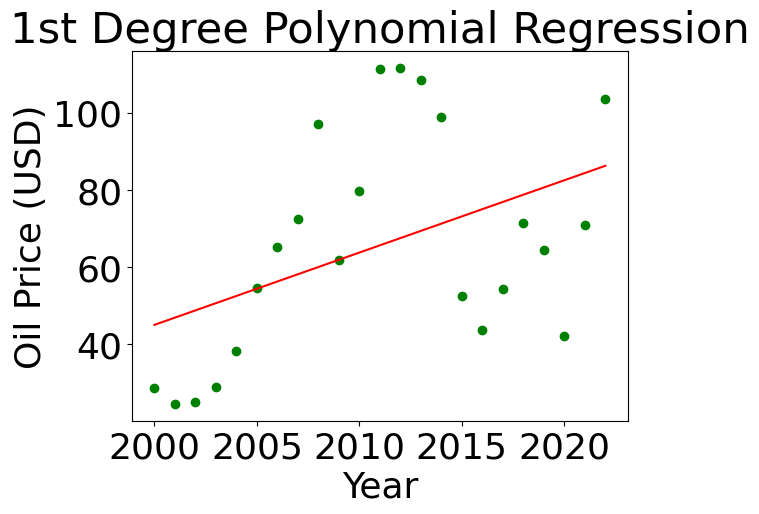

In [38]:
# 1st Degree Polynomial Regression visualization
plt.scatter(x, y, color='green')
plt.plot(x, y_pred, color = 'red')

# Properties
plt.title("1st Degree Polynomial Regression")
plt.xlabel('Year')
plt.ylabel('Oil Price (USD)')
plt.rcParams['font.size']=12

plt.show()

### Training the Polynomial Regression Model using Degree 3

In [39]:
# Polynomial function order
order = 3

x = df_clean.Date.values # regressor
y = df_clean.Price # regressand
p_array = np.polyfit(x,y,order)

print(type(p_array), p_array)
p = np.poly1d(p_array)
print(type(p), p)
print('The value of the polynomial for x = 2020 is : {} '.format(p(2020)))

e = np.abs(y-p(x))
mse = np.sum(e**2)/len(x)

print('The estimated polynomial parameters are: {}'.format(p))
print('The errors for each value of x, given the estimated polynomial parameters are: \n {}'.format(e))
print('The MSE is :{}'.format(mse))

<class 'numpy.ndarray'> [ 2.91149749e-02 -1.76012281e+02  3.54687523e+05 -2.38245719e+08]
<class 'numpy.poly1d'>          3       2
0.02911 x - 176 x + 3.547e+05 x - 2.382e+08
The value of the polynomial for x = 2020 is : 69.58949685096741 
The estimated polynomial parameters are:          3       2
0.02911 x - 176 x + 3.547e+05 x - 2.382e+08
The errors for each value of x, given the estimated polynomial parameters are: 
 0     25.003636
1      3.992744
2      9.805489
3     17.988215
4     18.498828
5     10.157358
6      5.772123
7      3.097980
8     18.221988
9     18.919466
10     1.912014
11    29.777557
12    30.841981
13    29.132898
14    21.227998
15    23.545361
16    30.319697
17    18.078855
18     0.560513
19     5.525025
20    27.488481
21     0.672277
22    31.677300
Name: Price, dtype: float64
The MSE is :390.04091182466664


In [40]:
poly_reg = PolynomialFeatures(degree=3)
X_poly = poly_reg.fit_transform(x.reshape(-1, 1))

In [41]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,y)


LinearRegression()

In [42]:
y_pred = lin_reg.predict(X_poly)


In [43]:
df = pd.DataFrame({'Real Values': y, 'Predicted Values':y_pred})

In [44]:
df

,Real Values,Predicted Values
0,28.660672,3.644767
1,24.455720,20.455998
2,24.993255,34.795933
3,28.850814,46.839367
4,38.259693,56.761095
5,54.574553,64.735913
6,65.161765,70.938615
7,72.441160,75.543998
8,96.944348,78.726856
9,61.738770,80.661986


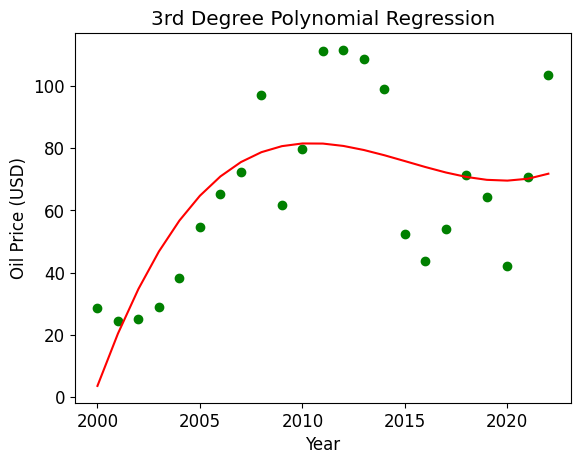

In [45]:
# 3rd Degree Polynomial Regression visualization
plt.scatter(x, y, color='green')
plt.plot(x, y_pred, color = 'red')

# Properties
plt.title("3rd Degree Polynomial Regression")
plt.xlabel('Year')
plt.ylabel('Oil Price (USD)')
plt.rcParams['font.size']=12

plt.show()

### Training the Polynomial Regression Model using Degree 5

In [46]:
# Polynomial function order
order = 5

x = df_clean.Date.values # regressor
y = df_clean.Price # regressand
p_array = np.polyfit(x,y,order)

print(type(p_array), p_array)
p = np.poly1d(p_array)
print(type(p), p)
print('The value of the polynomial for x = 2020 is : {} '.format(p(2020)))

e = np.abs(y-p(x))
mse = np.sum(e**2)/len(x)

print('The estimated polynomial parameters are: {}'.format(p))
print('The errors for each value of x, given the estimated polynomial parameters are: \n {}'.format(e))
print('The MSE is :{}'.format(mse))

<class 'numpy.ndarray'> [ 2.20266524e-04 -2.20363480e+00  8.81819077e+03 -1.76432277e+07
  1.76496131e+10 -7.06221371e+12]
<class 'numpy.poly1d'>            5         4        3             2
0.0002203 x - 2.204 x + 8818 x - 1.764e+07 x + 1.765e+10 x - 7.062e+12
The value of the polynomial for x = 2020 is : 55.3466796875 
The estimated polynomial parameters are:            5         4        3             2
0.0002203 x - 2.204 x + 8818 x - 1.764e+07 x + 1.765e+10 x - 7.062e+12
The errors for each value of x, given the estimated polynomial parameters are: 
 0      0.174289
1      0.448884
2      0.078034
3      1.850358
4      1.266674
5      4.268888
6      3.346335
7      0.550051
8     14.066418
9     28.941894
10    16.205009
11    13.383415
12    14.836308
13    16.041328
14    13.345583
15    24.482279
16    23.502625
17     3.966016
18    19.826211
19    14.633322
20    13.245664
21     0.865367
22     0.952155
Name: Price, dtype: float64
The MSE is :179.11090933800642


In [65]:
poly_reg = PolynomialFeatures(degree=5)
X_poly = poly_reg.fit_transform(x.reshape(-1, 1))

In [66]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,y)


LinearRegression()

In [67]:
y_pred = lin_reg.predict(X_poly)


In [68]:
df = pd.DataFrame({'Real Values': y, 'Predicted Values':y_pred})

In [69]:
df

,Real Values,Predicted Values
0,28.660672,3.587065
1,24.455720,20.411009
2,24.993255,34.770053
3,28.850814,46.835499
4,38.259693,56.779177
5,54.574553,64.773439
6,65.161765,70.991164
7,72.441160,75.605758
8,96.944348,78.791150
9,61.738770,80.721801


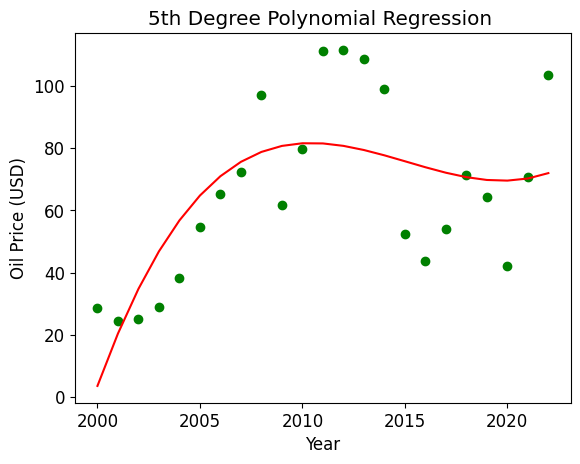

In [70]:
# 5th Degree Polynomial Regression visualization
plt.scatter(x, y, color='green')
plt.plot(x, y_pred, color = 'red')

# Properties
plt.title("5th Degree Polynomial Regression ")
plt.xlabel('Year')
plt.ylabel('Oil Price (USD)')
plt.rcParams['font.size']=12

plt.show()

#Conclusion
The activity successfully demonstrates building a polynomial regression model and evaluate its performance. Polynomial regression uses powers to fit the real data values, and have seen its importance in the procedure. I am able to learn about the step-by-step process on polynomial regression in model building through applying it to the yearly internet traffic volume dataset. Upon doing it, we can see that different degrees will return different regression lines, and the 3rd degree fit best with the given data. We were also able to assess the model's accuracy with visualizing the absolute errors and mean square errors of each polynomial regression model.<br><br>
The supplementary activity lets us apply these concepts in a different dataset, where I chose the yearly oil prices from 2000 to 2022 in USD. Firstly, data cleaning and manipulation is essential to ensure no missing values are included in the dataset, data types and formats are uniform, and limited to the data scientist's scope and goal. Upon performance checking, we can see that the created models do not really fit the real data with some fluctuations in some years. Absolute and predicted errors were also high on all models. I believe the reason being is the inserted data in the model was not cleaned properly or balanced to a normal distribution. Another reason could be that a different regression model may be applicable in the given dataset, instead of the polynomial regression.<br><br>
Overall, the activity served as familiarization of polynomial regression. I can say that I was able to grasp its importance and application.